In [1]:
# ====================================================
# Libraries
# ====================================================

import numpy as np
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

In [2]:
# ====================================================
# File paths
# ====================================================

# Update the paths below to match your local clone
fname_noFRB = "/home/brunowesley/projetos/MCMC-cosmo/Codes/MCMC-Models/MG-based/Appleby-Battye/CC_SNe_BAO/flat_samples_AB_cc_sne_bao.npy"
fname_FRB   = "/home/brunowesley/projetos/MCMC-cosmo/Codes/MCMC-Models/MG-based/Appleby-Battye/CC_SNe_BAO_FRB/flat_samples_AB_cc_sne_bao_frb.npy"


# ====================================================
# Load samples (FULL chains)
# ====================================================

samples_noFRB_full = np.load(fname_noFRB)
samples_FRB_full   = np.load(fname_FRB)

print("No FRB (full):", samples_noFRB_full.shape)
print("With FRB (full):", samples_FRB_full.shape)

No FRB (full): (3816920, 5)
With FRB (full): (4421928, 7)


In [3]:
# ====================================================
# Function: marginalized statistics (PRINT + SAVE)
# ====================================================

def print_stats(flat_samples, param_names_indices, fmt_map, title,
                file=None, one_sided_params=None):

    if one_sided_params is None:
        one_sided_params = []

    lines = []
    lines.append("\n" + "="*60)
    lines.append(f"{title:^60}")
    lines.append("="*60)

    for name, idx in param_names_indices:
        samples = flat_samples[:, idx]
        fmt     = fmt_map.get(name, ".3f")

        lines.append(f"\n  {name}:")

        # ====================================================
        # ONE-SIDED CASE (e.g. b)
        # ====================================================
        if name in one_sided_params:

            lower68 = np.percentile(samples, 16)
            lower95 = np.percentile(samples, 5)

            lines.append(f"    > {lower68:{fmt}}  (68% CL)")
            lines.append(f"    > {lower95:{fmt}}  (95% CL)")

        # ====================================================
        # STANDARD CASE
        # ====================================================
        else:
            median  = np.percentile(samples, 50)
            lower68 = np.percentile(samples, 16)
            upper68 = np.percentile(samples, 84)
            lower95 = np.percentile(samples, 2.5)
            upper95 = np.percentile(samples, 97.5)

            ep68 = upper68 - median
            em68 = median  - lower68
            ep95 = upper95 - median
            em95 = median  - lower95

            lines.append(f"    {median:{fmt}} +{ep68:{fmt}} -{em68:{fmt}}  (68% CL)")
            lines.append(f"    {median:{fmt}} +{ep95:{fmt}} -{em95:{fmt}}  (95% CL)")

    lines.append("\n" + "="*60)

    # ---- Print
    for line in lines:
        print(line)

    # ---- Save
    if file is not None:
        for line in lines:
            file.write(line + "\n")


# ====================================================
# Save ALL output
# ====================================================

output_file = "stats_AB_full.txt"

with open(output_file, "w", encoding="utf-8") as f:

    # ====================================================
    # WITHOUT FRB
    # ====================================================

    param_noFRB = [
        ("H0", 0),
        ("Om0", 1),
        ("Ob", 2),
        ("MB", 3),
        ("b", 4)
    ]

    fmt_noFRB = {
        "H0": ".2f",
        "Om0": ".3f",
        "Ob": ".4f",
        "MB": ".3f",
        "b": ".3f"
    }

    print_stats(
        samples_noFRB_full,
        param_noFRB,
        fmt_noFRB,
        "AB | CC + SNe + BAO",
        file=f,
        one_sided_params=["b"]   # one-sided: lower limit only
    )

    # ====================================================
    # WITH FRB
    # ====================================================

    param_FRB = [
        ("H0", 0),
        ("Om0", 1),
        ("Ob", 2),
        ("MB", 3),
        ("b", 4),
        ("sigma_host", 5),
        ("exp_mu", 6)
    ]

    fmt_FRB = {
        "H0": ".2f",
        "Om0": ".3f",
        "Ob": ".4f",
        "MB": ".3f",
        "b": ".3f",
        "sigma_host": ".3f",
        "exp_mu": ".1f"
    }

    print_stats(
        samples_FRB_full,
        param_FRB,
        fmt_FRB,
        "AB | CC + SNe + BAO + FRB",
        file=f,
        one_sided_params=["b"]   # one-sided: lower limit only
    )

print(f"\n✅ Full output saved to: {output_file}")


                    AB | CC + SNe + BAO                     

  H0:
    68.71 +1.56 -1.61  (68% CL)
    68.71 +3.06 -3.30  (95% CL)

  Om0:
    0.308 +0.009 -0.008  (68% CL)
    0.308 +0.024 -0.016  (95% CL)

  Ob:
    0.0474 +0.0026 -0.0024  (68% CL)
    0.0474 +0.0055 -0.0047  (95% CL)

  MB:
    -19.387 +0.048 -0.049  (68% CL)
    -19.387 +0.092 -0.097  (95% CL)

  b:
    > 6.123  (68% CL)
    > 4.240  (95% CL)


                 AB | CC + SNe + BAO + FRB                  

  H0:
    70.42 +1.06 -1.10  (68% CL)
    70.42 +2.05 -2.36  (95% CL)

  Om0:
    0.305 +0.008 -0.008  (68% CL)
    0.305 +0.019 -0.015  (95% CL)

  Ob:
    0.0502 +0.0017 -0.0017  (68% CL)
    0.0502 +0.0035 -0.0034  (95% CL)

  MB:
    -19.336 +0.032 -0.033  (68% CL)
    -19.336 +0.062 -0.066  (95% CL)

  b:
    > 6.319  (68% CL)
    > 4.767  (95% CL)

  sigma_host:
    0.834 +0.123 -0.102  (68% CL)
    0.834 +0.266 -0.185  (95% CL)

  exp_mu:
    104.3 +16.1 -15.9  (68% CL)
    104.3 +32.5 -31.0  (95% CL)


✅

Removed no burn in
Removed no burn in


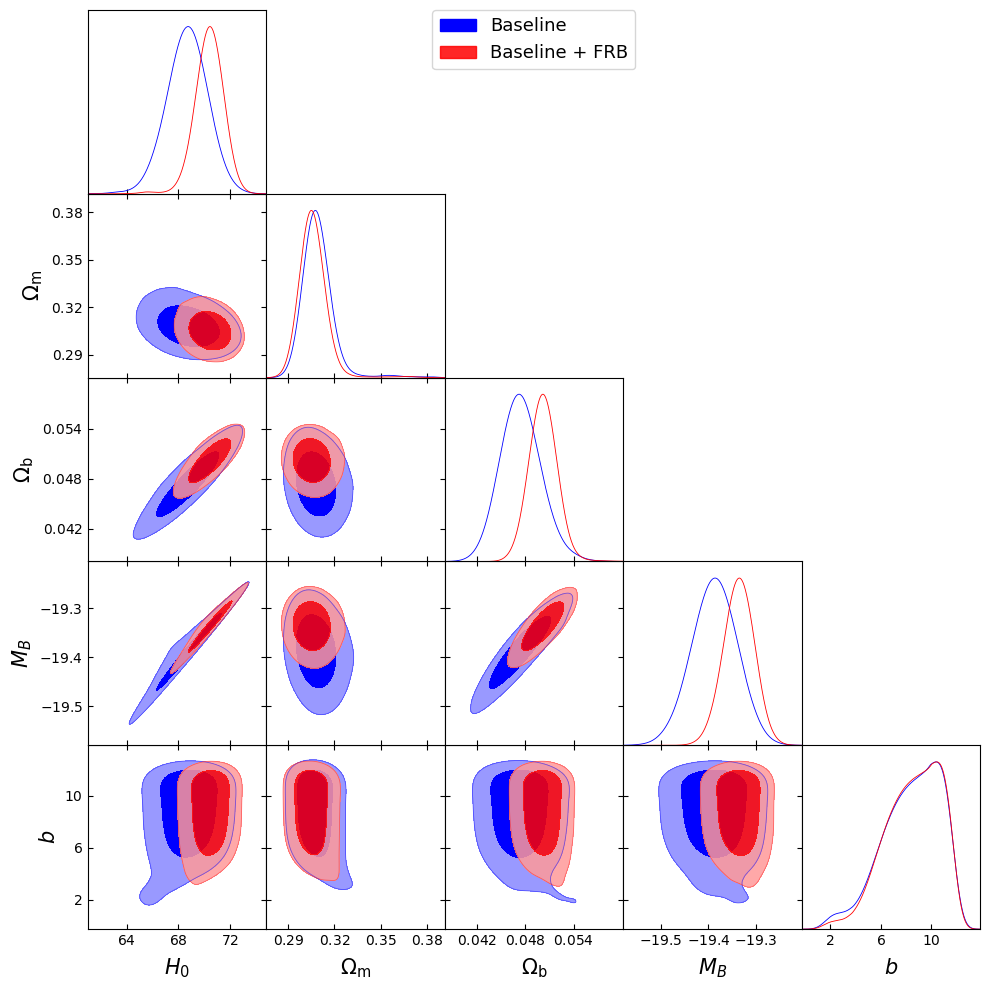

In [4]:
# ====================================================
# Parameters for corner plot
# ====================================================

idx = [0, 1, 2, 3, 4]

samples_noFRB = samples_noFRB_full[:, idx]
samples_FRB   = samples_FRB_full[:, idx]

param_names  = ["H0", "Om0", "Ob", "MB", "b"]
param_labels = [r"H_0", r"\Omega_{\rm m}", r"\Omega_{\rm b}", r"M_B", r"b"]

# ====================================================
# GetDist
# ====================================================

gd_noFRB = MCSamples(samples=samples_noFRB,
                     names=param_names,
                     labels=param_labels)

gd_FRB   = MCSamples(samples=samples_FRB,
                     names=param_names,
                     labels=param_labels)

for gd in [gd_noFRB, gd_FRB]:
    gd.updateSettings({
        "smooth_scale_1D": 0.35,
        "smooth_scale_2D": 0.35,
        "fine_bins": 1024,
        "fine_bins_2D": 1024,
    })

# ====================================================
# Corner plot
# ====================================================

g = plots.get_subplot_plotter()
g.settings.axes_labelsize = 18
g.settings.axes_fontsize = 13
g.settings.legend_fontsize = 16

g.triangle_plot(
    [gd_noFRB, gd_FRB],
    filled=True,
    legend_labels=[r"Baseline", r"Baseline + FRB"],
    contour_colors=["blue", "red"],
    title_limit=0
)

# ====================================================
# Explicit tick values: H0, Om0, Ob (vertical and horizontal)
# ====================================================
# Checked against the real chains: H0 in [61.0, 74.8], Om0 in [0.276,
# 0.392], Ob in [0.038, 0.060] -- all requested values fit.

from matplotlib.ticker import FixedLocator

for row in range(len(param_names)):
    for col in range(len(param_names)):
        ax = g.subplots[row, col]
        if ax is None:
            continue
        xname = param_names[col]
        if xname == "H0":
            ax.xaxis.set_major_locator(FixedLocator([64, 68, 72]))
        elif xname == "Om0":
            ax.xaxis.set_major_locator(FixedLocator([0.29, 0.32, 0.35, 0.38]))
        elif xname == "Ob":
            ax.xaxis.set_major_locator(FixedLocator([0.042, 0.048, 0.054]))
        if row != col:
            yname = param_names[row]
            if yname == "Om0":
                ax.yaxis.set_major_locator(FixedLocator([0.29, 0.32, 0.35, 0.38]))
            elif yname == "Ob":
                ax.yaxis.set_major_locator(FixedLocator([0.042, 0.048, 0.054]))

plt.savefig("Corner_AB_comparison.png", dpi=300, bbox_inches="tight")
plt.savefig("Corner_AB_comparison.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
# ====================================================
# Derived parameter: sound horizon rd
# ====================================================

Neff = 3.046 

def compute_rd_chain(flat_samples):
    H0  = flat_samples[:, 0]
    Om0 = flat_samples[:, 1]
    Ob  = flat_samples[:, 2]

    h2   = (H0 / 100.0)**2
    Obh2 = Ob * h2
    Omh2 = Om0 * h2

    rd = 147.05 * ((Obh2 / 0.02236)**-0.13) \
                 * ((Omh2 / 0.1432)**-0.23) \
                 * ((Neff  / 3.04)**-0.1)

    return rd


def print_rd_stats(rd_chain, title):

    median  = np.percentile(rd_chain, 50)
    lower68 = np.percentile(rd_chain, 16)
    upper68 = np.percentile(rd_chain, 84)
    lower95 = np.percentile(rd_chain, 2.5)
    upper95 = np.percentile(rd_chain, 97.5)

    ep68 = upper68 - median
    em68 = median  - lower68
    ep95 = upper95 - median
    em95 = median  - lower95

    print("\n" + "="*60)
    print(f"{title:^60}")
    print("="*60)

    print(f"\n  r_d:")
    print(f"    {median:.3f} +{ep68:.3f} -{em68:.3f}  (68% CL)")
    print(f"    {median:.3f} +{ep95:.3f} -{em95:.3f}  (95% CL)")

    print("\n" + "="*60)


# ====================================================
# Compute rd
# ====================================================

rd_noFRB = compute_rd_chain(samples_noFRB_full)
rd_FRB   = compute_rd_chain(samples_FRB_full)

print_rd_stats(rd_noFRB, "Sound Horizon r_d | CC + SNe + BAO")
print_rd_stats(rd_FRB,   "Sound Horizon r_d | CC + SNe + BAO + FRB")


             Sound Horizon r_d | CC + SNe + BAO             

  r_d:
    146.407 +3.268 -3.111  (68% CL)
    146.407 +6.596 -5.975  (95% CL)


          Sound Horizon r_d | CC + SNe + BAO + FRB          

  r_d:
    143.111 +2.185 -2.078  (68% CL)
    143.111 +4.417 -3.996  (95% CL)

